In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_curve, roc_auc_score

# PARAMETRI

In [2]:
EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


In [3]:
# DATASET SINTETICO: gaussiana standard in 3D (dati normali) + punti con media spostata (anomalie)
D = 3
N_TRAIN = 10000
N_TEST = 1000
N_ANOMALIES = 10

rng = np.random.default_rng(0)
mean = np.zeros(D)
cov = np.full((D, D), 0.9)
np.fill_diagonal(cov, 1.0)            # variabili fortemente correlate: i dati stanno vicino alla diagonale (1, 1, 1)
shift = np.array([1.0, -1.0, 0.0])
x_train = rng.multivariate_normal(mean, cov, N_TRAIN)                  # solo dati normali
x_normal = rng.multivariate_normal(mean, cov, N_TEST - N_ANOMALIES)
anomalies = rng.multivariate_normal(mean + shift, cov, N_ANOMALIES)
x_test = np.concatenate((anomalies, x_normal))                         # le anomalie sono i primi N_ANOMALIES punti
y_test = np.array([1] * N_ANOMALIES + [0] * (N_TEST - N_ANOMALIES))   # 1 = anomalia, 0 = normale

# Le etichette del training set sono fittizie (tutti 0): servono solo perché i loader restituiscano (x, y) come per MNIST
train_dataset = TensorDataset(torch.tensor(x_train, dtype=torch.float32), torch.zeros(N_TRAIN, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(x_test, dtype=torch.float32), torch.tensor(y_test))
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"TRAIN SET shape: {x_train.shape}")
print(f"TEST SET shape:  {x_test.shape}  ({N_ANOMALIES} anomalie)")

for x, y, title in [(x_train, None, 'Training set'),
                    (x_test, y_test, 'Test set (in giallo le anomalie)')]:
    fig = go.Figure(data=[go.Scatter3d(x=x[:, 0], y=x[:, 1], z=x[:, 2], mode='markers',
                                       marker=dict(color=y))])
    fig.update_layout(title=title,
                      scene=dict(xaxis=dict(range=[-5, 5]), yaxis=dict(range=[-5, 5]), zaxis=dict(range=[-5, 5])))
    fig.show()

TRAIN SET shape: (10000, 3)
TEST SET shape:  (1000, 3)  (10 anomalie)


# MODELLO

In [37]:
#Parametri del modello
INPUT_SIZE = D      # 3
LATENT_SIZE = 1

In [38]:
encoder = nn.Sequential(
    nn.Linear(INPUT_SIZE, LATENT_SIZE),  # (B, 3) -> (B, 1)
)

decoder = nn.Sequential(
    nn.Linear(LATENT_SIZE, INPUT_SIZE),# (B, 1) -> (B, 3), uscita lineare: i dati non sono limitati
)

autoencoder = nn.Sequential(encoder, decoder).to(DEVICE)

# Versione equivalente come classe:
# class AutoEncoder(nn.Module):
#     def __init__(self, input_size, latent_size):
#         super().__init__()
#         self.encoder = nn.Sequential(nn.Linear(input_size, latent_size), nn.ReLU())
#         self.decoder = nn.Sequential(nn.Linear(latent_size, input_size))
#     def forward(self, x):
#         return self.decoder(self.encoder(x))
# autoencoder = AutoEncoder(INPUT_SIZE, LATENT_SIZE).to(DEVICE)
# encoder = autoencoder.encoder

optimizer = torch.optim.Adam(autoencoder.parameters(), lr=LEARNING_RATE, eps=1e-7)
criterion = nn.MSELoss()

autoencoder

Sequential(
  (0): Sequential(
    (0): Linear(in_features=3, out_features=1, bias=True)
  )
  (1): Sequential(
    (0): Linear(in_features=1, out_features=3, bias=True)
  )
)

# ADDESTRAMENTO

100%|██████████| 30/30 [00:21<00:00,  1.41it/s]


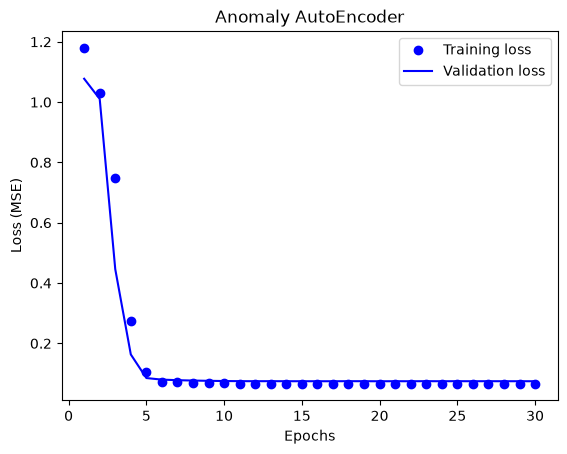

In [39]:
os.makedirs('histories', exist_ok=True)

filename = "anomaly1"
hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'

if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history_dict = pickle.load(hist_file)
    autoencoder.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history_dict = utils.train_autoencoder(autoencoder, optimizer, criterion,
                                     train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(autoencoder.state_dict(), weights_path)

epochs = range(1, len(history_dict['loss']) + 1)
plt.figure()
plt.plot(epochs, history_dict['loss'], 'bo', label='Training loss')
plt.plot(epochs, history_dict['val_loss'], 'b', label='Validation loss')
plt.title('Anomaly AutoEncoder')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend(loc='upper right')
plt.show()

# VALUTAZIONE

In [40]:
# TEST: ricostruzione dei punti del test set
autoencoder.eval()
x, y = test_dataset.tensors
with torch.no_grad():
    x_rec = autoencoder(x.to(DEVICE)).cpu().numpy()
x, y = x.numpy(), y.numpy()

fig = go.Figure()
for mask, name, color in [(y == 0, 'Normali', 'royalblue'), (y == 1, 'Anomalie', 'orange')]:
    fig.add_trace(go.Scatter3d(x=x[mask, 0], y=x[mask, 1], z=x[mask, 2], mode='markers',
                               name=name, marker=dict(size=3, color=color)))
fig.add_trace(go.Scatter3d(x=x_rec[:, 0], y=x_rec[:, 1], z=x_rec[:, 2], mode='markers',
                           name='Ricostruzioni', marker=dict(size=3, color='red')))
fig.update_layout(title='Punti del test set e loro ricostruzioni',
                  scene=dict(xaxis=dict(range=[-5, 5]), yaxis=dict(range=[-5, 5]), zaxis=dict(range=[-5, 5])))
fig.show()

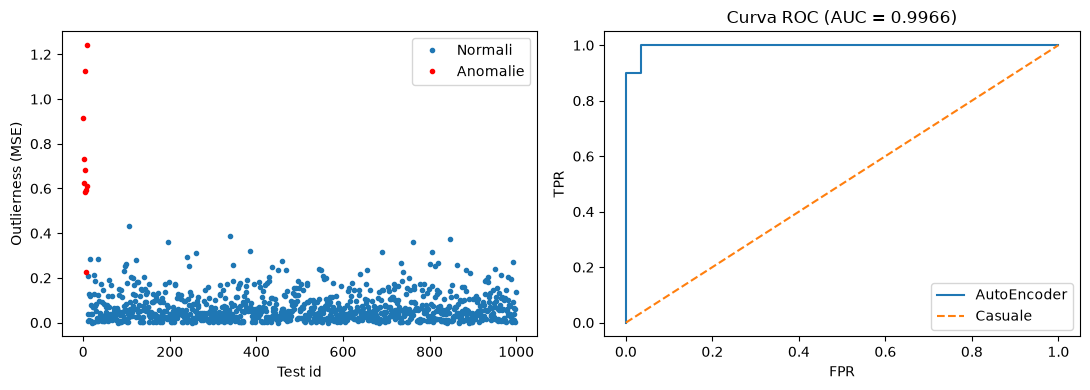

In [42]:
# ANOMALY DETECTION: l'outlierness di un punto è il suo errore di ricostruzione (MSE)
autoencoder.eval()
scores, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        x_rec = autoencoder(x.to(DEVICE)).cpu()
        scores.append(((x_rec - x) ** 2).mean(dim=1))   # MSE di ogni singolo punto
        labels.append(y)
outlierness = torch.cat(scores).numpy()
labels = torch.cat(labels).numpy()

fpr, tpr, thresholds = roc_curve(labels, outlierness)
auc = roc_auc_score(labels, outlierness)

ids = np.arange(len(outlierness))
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(ids[labels == 0], outlierness[labels == 0], '.', label='Normali')
plt.plot(ids[labels == 1], outlierness[labels == 1], '.', color='red', label='Anomalie')
plt.xlabel('Test id')
plt.ylabel('Outlierness (MSE)')
plt.legend(loc='upper right')
plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, label='AutoEncoder')
plt.plot([0, 1], [0, 1], linestyle='--', label='Casuale')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title(f'Curva ROC (AUC = {auc:.4f})')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()